# Ranh giới quyết định của mạng nơ-ron với số nơ-ron ẩn khác nhau (mục 9.1.3)

Lớp ẩn dùng hàm kích hoạt tanh, tối ưu bằng L-BFGS

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu với codes/03_backpropagation_numpy.ipynb

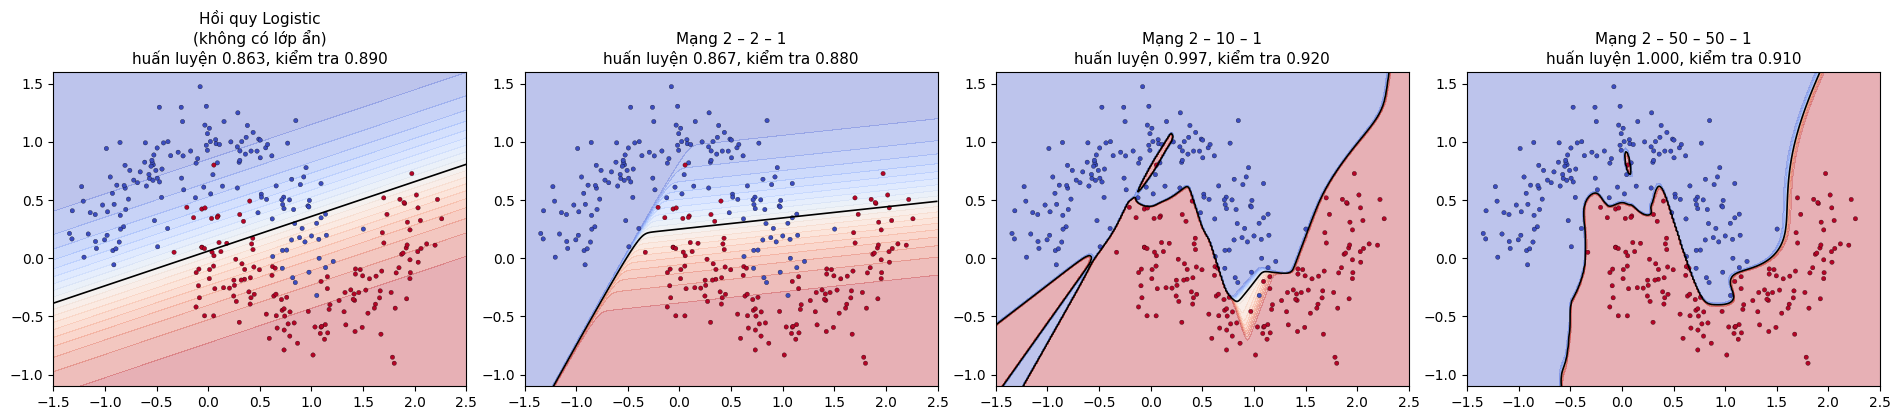

In [2]:
X, y = make_moons(n_samples=400, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

models = [('Hồi quy Logistic\n(không có lớp ẩn)', LogisticRegression()),
          ('Mạng 2 – 2 – 1', MLPClassifier(hidden_layer_sizes=(2,), activation='tanh', solver='lbfgs', max_iter=5000, random_state=0)),
          ('Mạng 2 – 10 – 1', MLPClassifier(hidden_layer_sizes=(10,), activation='tanh', solver='lbfgs', max_iter=5000, random_state=0)),
          ('Mạng 2 – 50 – 50 – 1', MLPClassifier(hidden_layer_sizes=(50, 50), activation='tanh', solver='lbfgs', max_iter=5000, random_state=0))]

xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 300), np.linspace(-1.1, 1.6, 300))
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (name, model) in zip(axes, models):
    model.fit(X_train, y_train)
    zz = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=0.35)
    ax.contour(xx, yy, zz, levels=[0.5], colors='k', linewidths=1.2)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=10, edgecolors='k', linewidths=0.2)
    ax.set_title('%s\nhuấn luyện %.3f, kiểm tra %.3f' % (name, model.score(X_train, y_train), model.score(X_test, y_test)),
                 fontsize=11)
fig.tight_layout()
fig.savefig(IMAGES / 'mlp_moons.png', dpi=150)